In [1]:
import json
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

from anomalies import add_tone, add_chirp, add_pulse, add_comb, add_ofdm, add_fsk

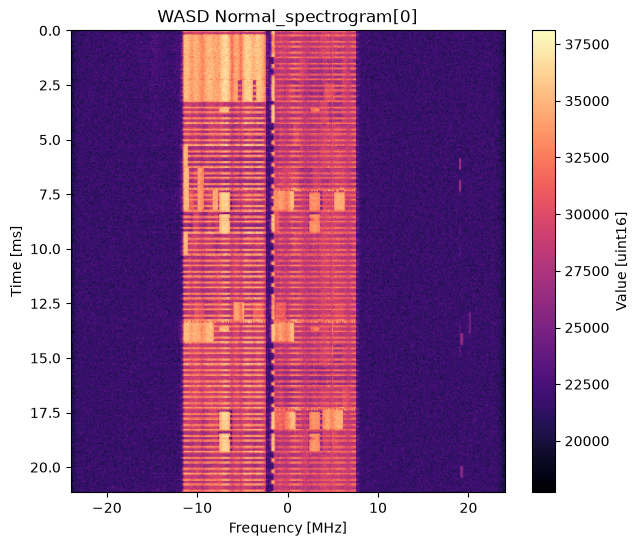

In [2]:
# WASD: 85 500 spectrograms, each 400 x 400 (rows = time, columns = frequency)
spectrograms = np.memmap("data/wasd/Normal_spectrogram.npy", dtype=np.uint16, mode="r").reshape(-1, 400, 400)

# Index 0 belongs to band 27_LTE_1: 21.16 ms of time, 48 MHz of bandwidth
plt.figure(figsize=(7, 6))
plt.imshow(spectrograms[0], cmap="magma", aspect="auto", extent=[-24, 24, 21.16, 0])
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title("WASD Normal_spectrogram[0]")
plt.colorbar(label="Value [uint16]")
plt.show()

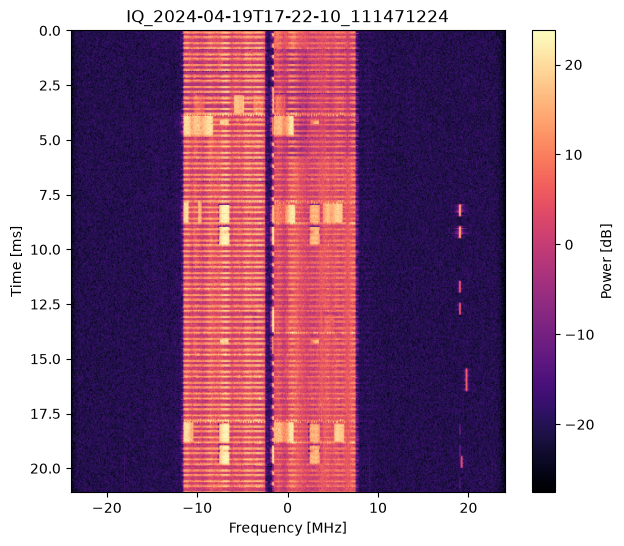

In [3]:
def iq_to_spectrogram(iq, fs):
    """WASD-style spectrogram in dB, shape (400 time, frequency), and its duration in ms."""
    # STFT with the same parameters as WASD (window 3200, hop 810)
    f, t, sxx = spectrogram(iq, fs=fs, window="hann", nperseg=3200, noverlap=2390,
                            return_onesided=False)
    f = np.fft.fftshift(f)
    sxx = np.fft.fftshift(sxx, axes=0)

    # Keep only the middle 48 MHz (the edges are guard bands)
    keep = np.abs(f) <= 24e6
    f, sxx = f[keep], sxx[keep]

    # Average every 4 frames: 1600 frames -> 400 rows, like WASD
    sxx = sxx[:, :1600].reshape(len(f), 400, 4).mean(axis=2)
    sxx_db = 10 * np.log10(sxx).T  # (time, frequency)
    return sxx_db, t[1599] * 1e3


# I/Q recording from band 27_LTE_1 (the same band as above)
name = "IQ_2024-04-19T17-22-10_111471224"
path = "data/iq/" + name
fs = json.load(open(path + ".json"))["sampling_frequency"]  # 61.44 MHz

# Interleaved int32 samples: I, Q, I, Q, ...
raw = np.fromfile(path + ".bin", dtype=np.int32)
iq = raw[0::2] + 1j * raw[1::2]

sxx_db, duration_ms = iq_to_spectrogram(iq, fs)

plt.figure(figsize=(7, 6))
plt.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
           vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
plt.xlabel("Frequency [MHz]")
plt.ylabel("Time [ms]")
plt.title(name)
plt.colorbar(label="Power [dB]")
plt.show()

In [ ]:
# One example of each anomaly type
rng = np.random.default_rng(0)  # random symbols for OFDM and FSK

examples = {
    "tone": add_tone(iq, fs, freq=15e6, start=5e-3, stop=10e-3, isr=-10),
    "chirp": add_chirp(iq, fs, f_start=-20e6, f_stop=20e6, start=2e-3, stop=18e-3, isr=-10),
    "pulse": add_pulse(iq, fs, freq=15e6, start=2e-3, stop=20e-3, isr=10),
    "comb": add_comb(iq, fs, f_first=12e6, spacing=2e6, n_tones=5, start=3e-3, stop=15e-3, isr=-10),
    "ofdm": add_ofdm(iq, fs, freq=16e6, bandwidth=5e6, start=8e-3, stop=20e-3, isr=-10, rng=rng),
    "fsk": add_fsk(iq, fs, freq=16e6, deviation=1.5e6, symbol_duration=0.5e-3,
                   start=3e-3, stop=18e-3, isr=-10, rng=rng),
}

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
for ax, (kind, iq_anomaly) in zip(axes.ravel(), examples.items()):
    sxx_db, duration_ms = iq_to_spectrogram(iq_anomaly, fs)
    ax.imshow(sxx_db, cmap="magma", aspect="auto", extent=[-24, 24, duration_ms, 0],
              vmin=np.percentile(sxx_db, 1), vmax=np.percentile(sxx_db, 99.9))
    ax.set_xlabel("Frequency [MHz]")
    ax.set_ylabel("Time [ms]")
    ax.set_title(name + " + " + kind)
plt.tight_layout()
plt.show()